<a href="https://colab.research.google.com/github/migstreva/C13-Grupo6/blob/main/sintonia_pid_grupo6_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sintonia de Controladores PID — Motor CC (Grupo 6)

**Sistemas Embarcados C13 — Projeto 1:** Sintonia do controlador PID a partir do modelo FOPDT (k, τ, θ) identificado pelo método de Sundaresan, utilizando as técnicas **CHR sem Sobrevalor (Tabela 3)** e **ITAE (Tabela 6)**, simulação do sistema em Malha Fechada e análise do método mais adequado ao critério de desempenho do grupo: **menor tempo de resposta**.

## 1. Instalação das bibliotecas


In [2]:
!pip install control

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 578.3/578.3 kB 12.3 MB/s eta 0:00:00


## 2. Importação das bibliotecas


In [5]:
import numpy as np                 # cálculos numéricos e vetores
import matplotlib.pyplot as plt    # gráficos
import control as ctrl             # funções de transferência, Padé e malha fechada
import pandas as pd                # tabela de parâmetros (Tabela 8)
from scipy.io import loadmat
import scipy.io as sio      # leitura do arquivo .mat do dataset

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


## 3. Carregamento do Dataset



In [4]:
from google.colab import files
arquivo = files.upload()

Saving Motor_G6.mat to Motor_G6.mat


## 4. Leitura dos Dados


In [9]:
d = sio.loadmat('Motor_G6.mat')
t = d['t'].ravel()
u = d['Degrau'].ravel()
y = d['Saida'].ravel()

print('Tamanho:', len(t))
print('t: de', t[0], 'até', t[-1])
print('Degrau: de', u[0], 'até', u[-1])
print('Saída (RPM) início:', y[:5])
print('Saída (RPM) fim:', y[-5:])

Tamanho: 601
t: de 0.0 até 60.0
Degrau: de 0.0 até 50.0
Saída (RPM) início: [ 1.5235854  -5.19992053  3.75225598  4.70282358 -9.75517594]
Saída (RPM) fim: [896.31658941 902.99595971 900.15450694 890.08448845 901.54927856]


## 5. Parâmetros do modelo FOPDT (Sundaresan)

In [11]:

k = 17.951609279384616       # ganho estático [RPM/%]
tau = 7.776452028082398      # constante de tempo [s]
theta = 0.9466405157382338   # atraso de transporte [s]

print('k     =', k)
print('tau   =', tau)
print('theta =', theta)
print('Fator de incontrolabilidade (theta/tau) =', theta/tau)

k     = 17.951609279384616
tau   = 7.776452028082398
theta = 0.9466405157382338
Fator de incontrolabilidade (theta/tau) = 0.12173167304571758


## 6. Sintonia CHR sem Sobrevalor

In [13]:
# Técnica 3 – CHR sem Sobrevalor
Kp_chr = 0.6 * tau / (k * theta)
Ti_chr = tau
Td_chr = theta / 2

print('Kp_chr =', Kp_chr)
print('Ti_chr =', Ti_chr)
print('Td_chr =', Td_chr)

Kp_chr = 0.27456442932057246
Ti_chr = 7.776452028082398
Td_chr = 0.4733202578691169


## 7. Sintonia ITAE

In [15]:
# Técnica 6 – ITAE
A, B, C, D, E, F = 0.965, -0.85, 0.796, -0.147, 0.308, 0.929

Kp_itae = (A / k) * (theta / tau) ** B
Ti_itae = tau / (C + D * (theta / tau))
Td_itae = tau * E * (theta / tau) ** F

print('Kp_itae =', Kp_itae)
print('Ti_itae =', Ti_itae)
print('Td_itae =', Td_itae)

Kp_itae = 0.3219814663801118
Ti_itae = 9.994085104306212
Td_itae = 0.3385884580940418


## 8. Tabela 8 – Parâmetros do PID

In [17]:


tabela8 = pd.DataFrame({
    'Técnica': [3, 6],
    'Método':  ['CHR sem Sobrevalor', 'ITAE'],
    'Kp':      [Kp_chr, Kp_itae],
    'Ti [s]':  [Ti_chr, Ti_itae],
    'Td [s]':  [Td_chr, Td_itae]
})

tabela8.round(4)

,Técnica,Método,Kp,Ti [s],Td [s]
0,3,CHR sem Sobrevalor,0.2746,7.7765,0.4733
1,6,ITAE,0.3220,9.9941,0.3386


## 9. Função de Transferência do modelo (FOPDT com Padé)

In [19]:
import control as cnt

H = cnt.tf([k], [tau, 1])           # planta de 1ª ordem: k / (tau*s + 1)

n_pade = 10                         # ordem da aproximação de Padé
num_pade, den_pade = cnt.pade(theta, n_pade)
H_atraso = cnt.tf(num_pade, den_pade)

H_modelo = cnt.series(H, H_atraso)  # junta planta + atraso em série
print(H_modelo)

<TransferFunction>: sys[5]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

           17.95 s^10 - 2086 s^9 + 1.19e+05 s^8 - 4.358e+06 s^7 + 1.128e+08 s^6 - 2.144e+09 s^5 + 3.02e+10 s^4 - 3.1e+11 s^3 + 2.21e+12 s^2 - 9.858e+12 s + 2.083e+13
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  7.776 s^11 + 904.6 s^10 + 5.166e+04 s^9 + 1.894e+06 s^8 + 4.91e+07 s^7 + 9.352e+08 s^6 + 1.32e+10 s^5 + 1.36e+11 s^4 + 9.747e+11 s^3 + 4.393e+12 s^2 + 9.571e+12 s + 1.16e+12


## 10. Controlador PID

In [21]:
s = cnt.tf('s')

def pid(Kp, Ti, Td, N=10):
    """PID da Eq. (8): Kp*(1 + 1/(Ti*s) + Td*s), com filtro na derivada (N = 10)."""
    return cnt.minreal(Kp * (1 + 1/(Ti*s) + Td*s / (1 + (Td/N)*s)), verbose=False)

C_chr = pid(Kp_chr, Ti_chr, Td_chr)      # controlador CHR sem Sobrevalor
C_itae = pid(Kp_itae, Ti_itae, Td_itae)  # controlador ITAE

print('PID – CHR sem Sobrevalor:')
print(C_chr)
print('PID – ITAE:')
print(C_itae)

PID – CHR sem Sobrevalor:
<TransferFunction>: sys[56]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  3.02 s^2 + 5.836 s + 0.7459
  ---------------------------
         s^2 + 21.13 s
PID – ITAE:
<TransferFunction>: sys[73]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  3.542 s^2 + 9.542 s + 0.9515
  ----------------------------
         s^2 + 29.53 s


## 11. Simulação em Malha Fechada com PID

In [23]:
SP = 900                            # SetPoint [RPM] – velocidade alvo do dataset
t_sim = np.linspace(0, 40, 4001)    # 40 s de simulação

controladores = {'CHR sem Sobrevalor': C_chr,
                 'ITAE': C_itae}

resultados = {}
for nome, C in controladores.items():
    H_mf = cnt.feedback(cnt.series(C, H_modelo), 1)        # malha fechada (Figura 10)
    t_out, y_out = cnt.step_response(SP * H_mf, t_sim)     # resposta ao degrau de SP
    info = cnt.step_info(SP * H_mf, T=t_sim, SettlingTimeThreshold=0.02)
    resultados[nome] = (t_out, y_out, info)

    print(f'{nome}:')
    print(f'  Tempo de subida (tr)      = {info["RiseTime"]:.2f} s')
    print(f'  Tempo de acomodação (ts)  = {info["SettlingTime"]:.2f} s')
    print(f'  Overshoot (Mp)            = {info["Overshoot"]:.2f} %')
    print(f'  Valor final               = {info["SteadyStateValue"]:.1f} RPM\n')

CHR sem Sobrevalor:
  Tempo de subida (tr)      = 2.40 s
  Tempo de acomodação (ts)  = 4.78 s
  Overshoot (Mp)            = 0.52 %
  Valor final               = 900.0 RPM

ITAE:
  Tempo de subida (tr)      = 0.93 s
  Tempo de acomodação (ts)  = 7.42 s
  Overshoot (Mp)            = 0.00 %
  Valor final               = 900.0 RPM



## 12. Gráfico: Malha Fechada com PID – CHR sem Sobrevalor x ITAE

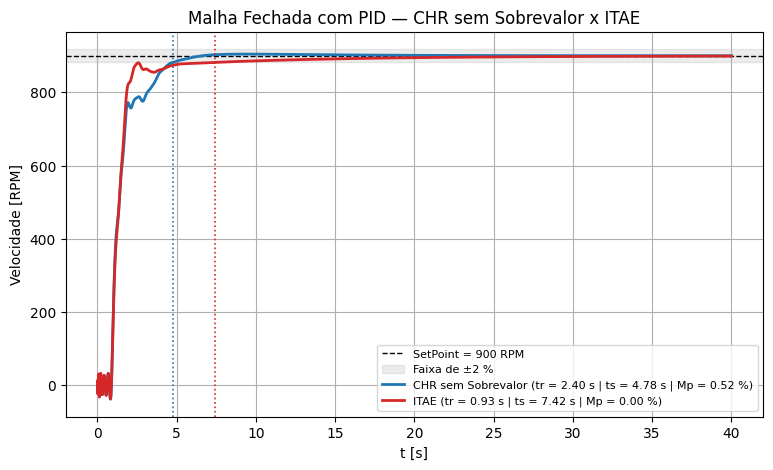

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
cores = {'CHR sem Sobrevalor': 'tab:blue', 'ITAE': 'tab:red'}

plt.figure(figsize=(9, 5))
plt.axhline(SP, color='k', ls='--', lw=1, label=f'SetPoint = {SP} RPM')
plt.axhspan(0.98*SP, 1.02*SP, color='gray', alpha=0.15, label='Faixa de ±2 %')

for nome, (t_out, y_out, info) in resultados.items():
    plt.plot(t_out, y_out, color=cores[nome], lw=2,
             label=f"{nome} (tr = {info['RiseTime']:.2f} s | "
                   f"ts = {info['SettlingTime']:.2f} s | Mp = {info['Overshoot']:.2f} %)")
    plt.axvline(info['SettlingTime'], color=cores[nome], ls=':', lw=1.2)  # marca o ts

plt.xlabel('t [s]')
plt.ylabel('Velocidade [RPM]')
plt.title('Malha Fechada com PID — CHR sem Sobrevalor x ITAE')
plt.legend(loc='lower right', fontsize=8)
plt.grid()
plt.savefig('malha_fechada_pid_grupo6.png', dpi=200, bbox_inches='tight')
plt.show()

from google.colab import files
files.download('malha_fechada_pid_grupo6.png')

## 13. Análise do desempenho – Item 6

**Critério de desempenho do Grupo 6:** (a) menor tempo de resposta.

| Método | Kp | Ti [s] | Td [s] | tr [s] | ts (2 %) [s] | Mp [%] | Erro em regime |
|---|---|---|---|---|---|---|---|
| CHR sem Sobrevalor | 0,2746 | 7,7765 | 0,4733 | 2,40 | **4,78** | 0,52 | 0 |
| ITAE | 0,3220 | 9,9941 | 0,3386 | **0,93** | 7,42 | 0,00 | 0 |

**Método mais adequado: CHR sem Sobrevalor (Técnica 3).**

O tempo de resposta de um sistema de controle é o tempo necessário para a saída atingir e **permanecer** no regime permanente, ou seja, o tempo de acomodação pelo critério dos 2 %. O CHR sem Sobrevalor leva o motor à velocidade de 900 RPM em **4,78 s**, contra **7,42 s** do ITAE, sendo aproximadamente **36 % mais rápido**.

O ITAE apresenta tempo de subida menor (0,93 s), pois possui ganho proporcional maior (Kp = 0,322 contra 0,275), o que gera uma reação inicial mais forte. Porém, após a subida, a velocidade estaciona em cerca de 98 % do SetPoint e se aproxima do valor final lentamente. Isso ocorre porque seu tempo integral (Ti ≈ 9,99 s) é maior que a constante de tempo da planta (τ ≈ 7,78 s), tornando a ação integral mais fraca para eliminar o erro residual.

No CHR sem Sobrevalor, o tempo integral é igual à constante de tempo (Ti = τ). Dessa forma, o zero do controlador cancela o polo da planta, e o erro residual é eliminado rapidamente, sem a "cauda" lenta observada no ITAE.

Além disso, o método CHR para o problema servo foi proposto justamente para obter **a resposta mais rápida possível sem sobressinal** diante de mudanças de SetPoint, o que coincide com o critério de desempenho do grupo. O pequeno overshoot obtido (0,52 %, cerca de 5 RPM) é desprezível, da mesma ordem do ruído do sensor no ensaio.

**Observação:** as pequenas oscilações próximas de zero no primeiro segundo do gráfico são um artefato numérico da aproximação de Padé do atraso de transporte. O sistema real permaneceria em 0 RPM até t = θ ≈ 0,95 s.